# Indian Automobile Market Analysis Using Python

### Exploratory Data Analysis of Vehicle Models, Pricing, Sales and EV Trends in India

## 1. Project Overview

This project performs Exploratory Data Analysis (EDA) on vehicle models available in the Indian automobile market.

The analysis focuses on understanding vehicle brands, models, segments, fuel types, pricing, monthly sales, EV adoption, mileage, variants, and notable features.

The objective is to identify meaningful patterns and relationships within the automobile market and derive actionable business insights from the available data.

## 2. Business Problem

The Indian automobile market consists of vehicles across multiple brands, segments, fuel types, price ranges, and technologies.

This project aims to analyze the available vehicle data to understand market structure, pricing patterns, sales performance, and the growing presence of electric vehicles.

The analysis will help identify trends and relationships that can provide useful insights into the Indian automobile market.

## 3. Project Objectives

- Analyze the distribution of vehicle brands, models, and segments.
- Understand vehicle pricing across different market segments.
- Analyze monthly sales across brands and vehicle categories.
- Compare electric vehicles with non-electric vehicles.
- Examine the relationship between vehicle specifications and pricing.
- Analyze market trends across launch years.
- Identify important patterns and relationships within the dataset.
- Generate meaningful business insights and recommendations.

## 4. Dataset Description

The dataset contains information about vehicle models and variants available in the Indian automobile market.

It includes information related to:

- Brand and Model
- Launch Year
- Vehicle Segment
- Fuel Type
- Number of Variants
- Ex-Showroom Price
- Monthly Sales
- EV Status
- Battery Capacity / Mileage
- Notable Features

The original dataset contains 15,000 vehicle records and 11 attributes. During data preparation, additional derived attributes such as Average Price, Mileage, and Range were created for further analysis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 5. Data Loading

### 5.1 Importing the Dataset

In [2]:
df = pd.read_csv('../data/indian_vehicle_data.csv')

In [3]:
df.head()

,Brand,Model,Launch Year,Segment,Fuel Type,Variants,Ex-Showroom Price (₹ Lakhs),Monthly Sales (Units),Is EV?,Battery / Mileage,Notable Features
0,Honda,Amaze,2019,Sedan,Petrol,12,6.00 - 15.00,13254,No,20.1 kmpl,"Hill Hold, ABS, Cruise Control, Leather Seats,..."
1,Nissan,Magnite,2019,Electric Hatchback,Petrol,3,6.00 - 12.00,4642,No,24.1 kmpl,"360 Camera, Hill Hold, Ventilated Seats, Leath..."
2,Tata,Harrier,2015,Compact SUV,Petrol/CNG,22,7.00 - 18.00,10650,No,22.0 kmpl,"TPMS, ADAS, EBD, Sunroof, Touchscreen, Cruise ..."
3,MG,Astor,2022,Electric Hatchback,Petrol,20,6.00 - 12.00,4381,No,21.4 kmpl,"EBD, Airbags, ADAS, Cruise Control, Ventilated..."
4,Nissan,Kicks,2015,SUV,Diesel,3,10.00 - 30.00,2944,No,25.2 kmpl,"Airbags, ABS, AC, Ventilated Seats, Touchscree..."


### 5.2 Dataset Shape

In [4]:
df.shape

(15000, 11)

### 5.3 Dataset Information

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 11 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   Brand                        15000 non-null  str  
 1   Model                        15000 non-null  str  
 2   Launch Year                  15000 non-null  int64
 3   Segment                      15000 non-null  str  
 4   Fuel Type                    15000 non-null  str  
 5   Variants                     15000 non-null  int64
 6   Ex-Showroom Price (₹ Lakhs)  15000 non-null  str  
 7   Monthly Sales (Units)        15000 non-null  int64
 8   Is EV?                       15000 non-null  str  
 9   Battery / Mileage            15000 non-null  str  
 10  Notable Features             15000 non-null  str  
dtypes: int64(3), str(8)
memory usage: 1.3 MB


### 5.4 Statistical Summary

In [6]:
df.describe()

,Launch Year,Variants,Monthly Sales (Units)
count,15000.000000,15000.000000,15000.000000
mean,2018.991067,13.174000,8664.002200
std,2.592753,7.200239,4941.852964
min,2015.000000,1.000000,150.000000
25%,2017.000000,7.000000,4563.000000
50%,2019.000000,13.000000,8521.500000
75%,2021.000000,19.000000,12368.000000
max,2023.000000,25.000000,19993.000000


### 5.5 Unique Values

In [7]:
df.nunique()

Brand                             20
Model                             75
Launch Year                        9
Segment                            8
Fuel Type                          5
Variants                          25
Ex-Showroom Price (₹ Lakhs)       16
Monthly Sales (Units)          10061
Is EV?                             2
Battery / Mileage                445
Notable Features               14994
dtype: int64

### 5.6 Duplicate Records

In [8]:
df.duplicated().sum()

np.int64(0)

### 5.7 Missing Values

In [9]:
df.isnull().sum()

Brand                          0
Model                          0
Launch Year                    0
Segment                        0
Fuel Type                      0
Variants                       0
Ex-Showroom Price (₹ Lakhs)    0
Monthly Sales (Units)          0
Is EV?                         0
Battery / Mileage              0
Notable Features               0
dtype: int64

### 5.8 Categorical Value Analysis

In [10]:
df['Brand'].unique()

<StringArray>
[        'Honda',        'Nissan',          'Tata',            'MG',
         'Lexus',         'Force',      'Mahindra',         'Skoda',
           'Kia',    'Volkswagen',      'Mercedes',       'Renault',
 'Maruti Suzuki',           'BYD',           'BMW',       'Citroen',
        'Toyota',       'Hyundai',          'Audi',          'Jeep']
Length: 20, dtype: str

In [11]:
df['Segment'].unique()

<StringArray>
[             'Sedan', 'Electric Hatchback',        'Compact SUV',
                'SUV',          'Hatchback',       'Electric SUV',
                'MPV',             'Luxury']
Length: 8, dtype: str

In [12]:
df['Fuel Type'].unique()

<StringArray>
['Petrol', 'Petrol/CNG', 'Diesel', 'Electric', 'Petrol/Diesel']
Length: 5, dtype: str

In [13]:
df['Is EV?'].unique()

<StringArray>
['No', 'Yes']
Length: 2, dtype: str

## 6. Data Cleaning

### 6.1 Examining Ex-Showroom Price

In [14]:
df['Ex-Showroom Price (₹ Lakhs)'].unique()

<StringArray>
[  '6.00 - 15.00',   '6.00 - 12.00',   '7.00 - 18.00',  '10.00 - 30.00',
    '3.50 - 8.50',  '12.00 - 25.00',   '4.20 - 11.05',   '8.00 - 20.00',
 '30.00 - 100.00',   '7.20 - 19.50',  '14.40 - 32.50',  '12.00 - 39.00',
   '8.40 - 23.40', '36.00 - 130.00',   '9.60 - 26.00',   '7.20 - 15.60']
Length: 16, dtype: str

#### Converting Price Range to Average Price

In [15]:
price_range = df['Ex-Showroom Price (₹ Lakhs)'].str.split(' - ')

df['Average Price (₹ Lakhs)'] = price_range.apply(
    lambda x: (float(x[0]) + float(x[1])) / 2
)

In [16]:
df[['Ex-Showroom Price (₹ Lakhs)', 'Average Price (₹ Lakhs)']].head(10)

,Ex-Showroom Price (₹ Lakhs),Average Price (₹ Lakhs)
0,6.00 - 15.00,10.5
1,6.00 - 12.00,9.0
2,7.00 - 18.00,12.5
3,6.00 - 12.00,9.0
4,10.00 - 30.00,20.0
5,7.00 - 18.00,12.5
6,10.00 - 30.00,20.0
7,3.50 - 8.50,6.0
8,12.00 - 25.00,18.5
9,7.00 - 18.00,12.5


### 6.2 Examining Battery / Mileage

In [17]:
df['Battery / Mileage'].unique()[:20]

<StringArray>
[   '20.1 kmpl',    '24.1 kmpl',    '22.0 kmpl',    '21.4 kmpl',
    '25.2 kmpl',    '21.5 kmpl',    '15.6 kmpl',    '19.0 kmpl',
    '16.2 kmpl',    '26.1 kmpl',    '22.2 kmpl',    '24.2 kmpl',
    '18.2 kmpl',    '16.4 kmpl', '326 km range',    '24.3 kmpl',
    '19.2 kmpl',    '18.9 kmpl',    '20.0 kmpl',    '23.8 kmpl']
Length: 20, dtype: str

#### Extracting Mileage and EV Range

In [18]:
df['Mileage (kmpl)'] = df['Battery / Mileage'].str.extract(r'([\d.]+)\s*kmpl')[0].astype(float)

In [19]:
df['Range (km)'] = df['Battery / Mileage'].str.extract(r'([\d.]+)\s*km range')[0].astype(float)

In [20]:
df[['Battery / Mileage', 'Mileage (kmpl)', 'Range (km)']].head(20)

,Battery / Mileage,Mileage (kmpl),Range (km)
0,20.1 kmpl,20.1,NaN
1,24.1 kmpl,24.1,NaN
2,22.0 kmpl,22.0,NaN
3,21.4 kmpl,21.4,NaN
4,25.2 kmpl,25.2,NaN
5,21.5 kmpl,21.5,NaN
6,15.6 kmpl,15.6,NaN
7,19.0 kmpl,19.0,NaN
8,16.2 kmpl,16.2,NaN
9,24.1 kmpl,24.1,NaN


### 6.3 Verifying Extracted Values

In [21]:
df[['Mileage (kmpl)', 'Range (km)']].notna().sum()

Mileage (kmpl)    13881
Range (km)         1119
dtype: int64

## 7. Exploratory Data Analysis (EDA)

The Exploratory Data Analysis phase focuses on understanding the Indian automobile market through vehicle brands, segments, fuel types, pricing, sales, and EV characteristics.

### 7.1 Final Dataset Overview

In [22]:
df.head()

,Brand,Model,Launch Year,Segment,Fuel Type,Variants,Ex-Showroom Price (₹ Lakhs),Monthly Sales (Units),Is EV?,Battery / Mileage,Notable Features,Average Price (₹ Lakhs),Mileage (kmpl),Range (km)
0,Honda,Amaze,2019,Sedan,Petrol,12,6.00 - 15.00,13254,No,20.1 kmpl,"Hill Hold, ABS, Cruise Control, Leather Seats,...",10.5,20.1,NaN
1,Nissan,Magnite,2019,Electric Hatchback,Petrol,3,6.00 - 12.00,4642,No,24.1 kmpl,"360 Camera, Hill Hold, Ventilated Seats, Leath...",9.0,24.1,NaN
2,Tata,Harrier,2015,Compact SUV,Petrol/CNG,22,7.00 - 18.00,10650,No,22.0 kmpl,"TPMS, ADAS, EBD, Sunroof, Touchscreen, Cruise ...",12.5,22.0,NaN
3,MG,Astor,2022,Electric Hatchback,Petrol,20,6.00 - 12.00,4381,No,21.4 kmpl,"EBD, Airbags, ADAS, Cruise Control, Ventilated...",9.0,21.4,NaN
4,Nissan,Kicks,2015,SUV,Diesel,3,10.00 - 30.00,2944,No,25.2 kmpl,"Airbags, ABS, AC, Ventilated Seats, Touchscree...",20.0,25.2,NaN


In [23]:
df.shape

(15000, 14)

In [24]:
df.columns

Index(['Brand', 'Model', 'Launch Year', 'Segment', 'Fuel Type', 'Variants',
       'Ex-Showroom Price (₹ Lakhs)', 'Monthly Sales (Units)', 'Is EV?',
       'Battery / Mileage', 'Notable Features', 'Average Price (₹ Lakhs)',
       'Mileage (kmpl)', 'Range (km)'],
      dtype='str')

### 7.2 Brand Distribution

Understanding the number of vehicle records represented by each brand helps us examine the representation of different brands within the dataset.

In [25]:
brand_counts = df['Brand'].value_counts()

brand_counts

Brand
Toyota           821
Volkswagen       804
Tata             798
Mercedes         772
Audi             770
MG               768
Skoda            762
Maruti Suzuki    762
Force            751
Kia              751
BYD              749
Nissan           748
Renault          746
Mahindra         737
BMW              723
Lexus            718
Jeep             716
Honda            706
Citroen          706
Hyundai          692
Name: count, dtype: int64

#### Number of Vehicle Records by Brand

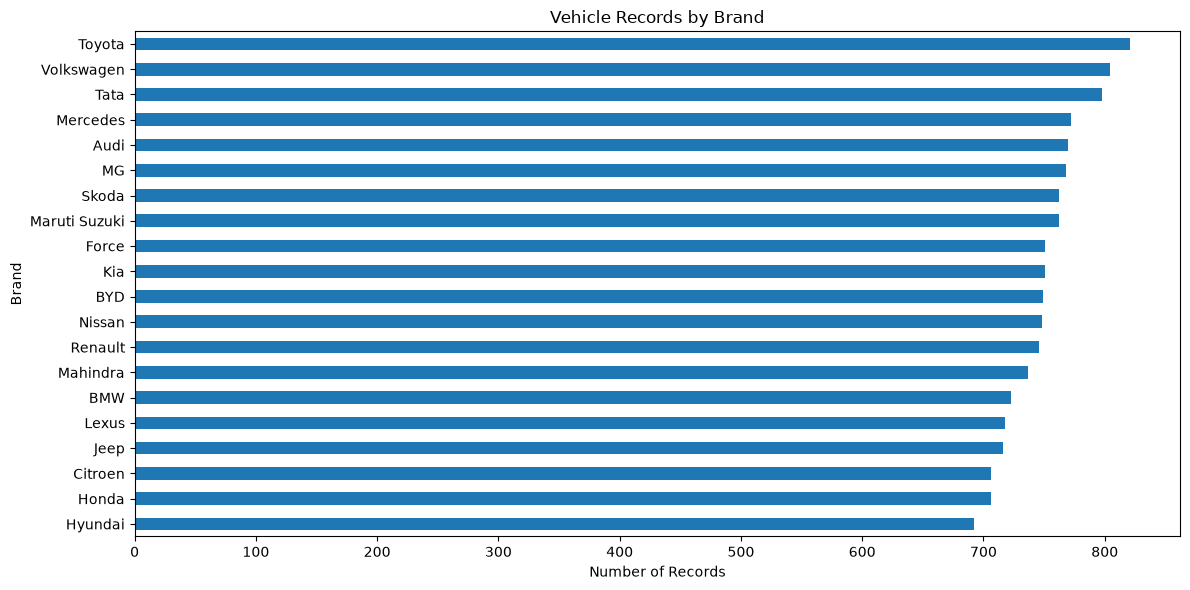

In [26]:
plt.figure(figsize=(12, 6))

brand_counts.sort_values().plot(kind='barh')

plt.title('Vehicle Records by Brand')
plt.xlabel('Number of Records')
plt.ylabel('Brand')
plt.tight_layout()
plt.show()

**Insight:**  
Toyota has the highest representation in the dataset with 821 records, while Hyundai has the lowest with 692 records. Overall, the number of records is relatively balanced across the 20 brands, indicating that the dataset does not heavily favor any single brand.

### 7.3 Vehicle Segment Distribution

In [27]:
segment_counts = df['Segment'].value_counts()

segment_counts

Segment
Hatchback             3773
Compact SUV           3717
Sedan                 2252
SUV                   2197
Electric SUV           789
Luxury                 782
Electric Hatchback     777
MPV                    713
Name: count, dtype: int64

#### Vehicle Records by Segment

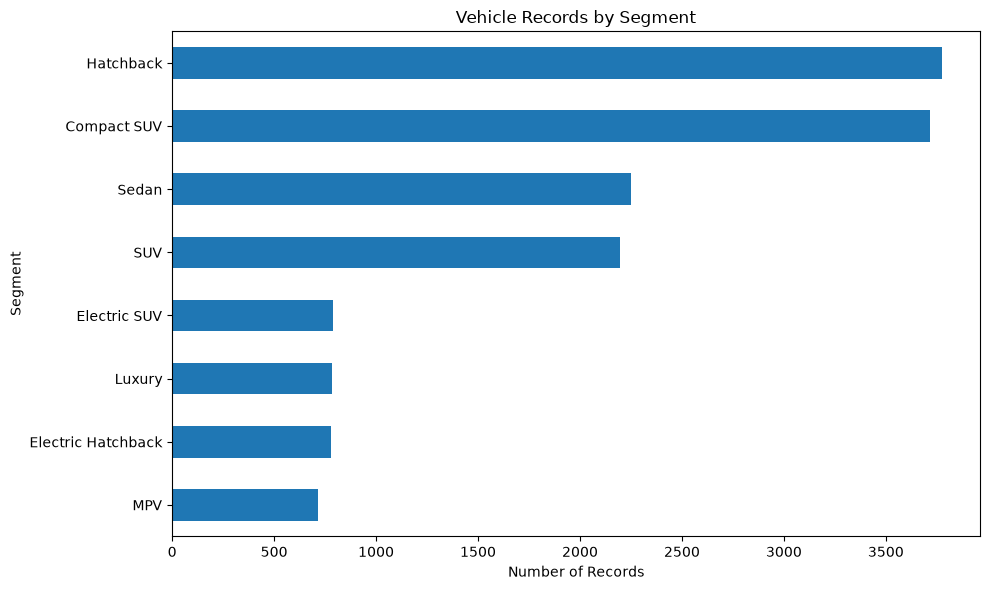

In [28]:
plt.figure(figsize=(10, 6))

segment_counts.sort_values().plot(kind='barh')

plt.title('Vehicle Records by Segment')
plt.xlabel('Number of Records')
plt.ylabel('Segment')
plt.tight_layout()
plt.show()

**Insight:**  
Hatchbacks and Compact SUVs have the highest representation in the dataset, with 3,773 and 3,717 records respectively. Sedans and SUVs follow with 2,252 and 2,197 records. MPVs, Electric Hatchbacks, Luxury vehicles, and Electric SUVs have comparatively lower representation.

### 7.4 Fuel Type Distribution

Understanding the distribution of fuel types helps examine the composition of the automobile dataset across conventional, dual-fuel, and electric vehicles.

In [29]:
fuel_counts = df['Fuel Type'].value_counts()

fuel_counts

Fuel Type
Petrol           8224
Diesel           3709
Petrol/CNG       1525
Electric         1119
Petrol/Diesel     423
Name: count, dtype: int64

#### Vehicle Records by Fuel Type

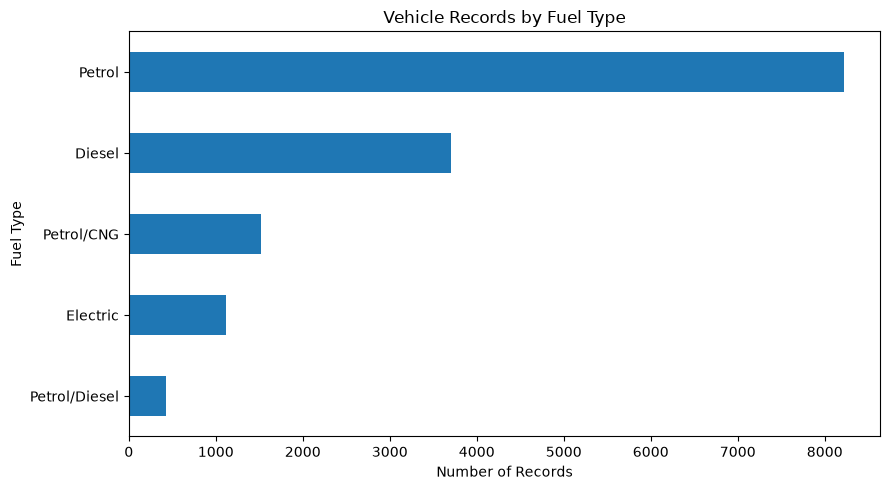

In [30]:
plt.figure(figsize=(9, 5))

fuel_counts.sort_values().plot(kind='barh')

plt.title('Vehicle Records by Fuel Type')
plt.xlabel('Number of Records')
plt.ylabel('Fuel Type')
plt.tight_layout()
plt.show()

**Insight:**  
Petrol vehicles dominate the dataset with 8,224 records, followed by Diesel with 3,709 records. Electric vehicles account for 1,119 records, while Petrol/CNG and Petrol/Diesel have lower representation.

### 7.5 EV vs Non-EV Analysis

Comparing electric and non-electric vehicles helps understand the representation of EVs within the automobile dataset.

In [31]:
ev_counts = df['Is EV?'].value_counts()

ev_counts

Is EV?
No     13881
Yes     1119
Name: count, dtype: int64

#### EV vs Non-EV Distribution

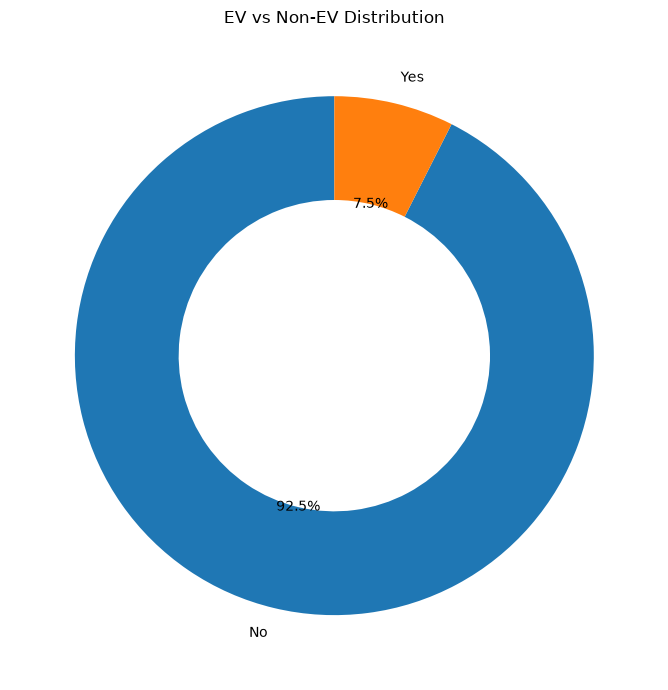

In [32]:
plt.figure(figsize=(7, 7))

plt.pie(
    ev_counts,
    labels=ev_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops={'width': 0.4}
)

plt.title('EV vs Non-EV Distribution')
plt.tight_layout()
plt.show()

**Insight:**  
Electric vehicles represent 7.5% of the dataset, while non-electric vehicles account for 92.5%. This shows that the dataset is still predominantly composed of non-EV vehicles, although EVs have a meaningful representation for further analysis.

### 7.6 Launch Year Distribution

Analyzing vehicle launch years helps identify how the dataset is distributed across different periods of the Indian automobile market.

In [33]:
launch_year_counts = df['Launch Year'].value_counts().sort_index()

launch_year_counts

Launch Year
2015    1742
2016    1609
2017    1664
2018    1681
2019    1641
2020    1699
2021    1606
2022    1673
2023    1685
Name: count, dtype: int64

#### Vehicle Records by Launch Year

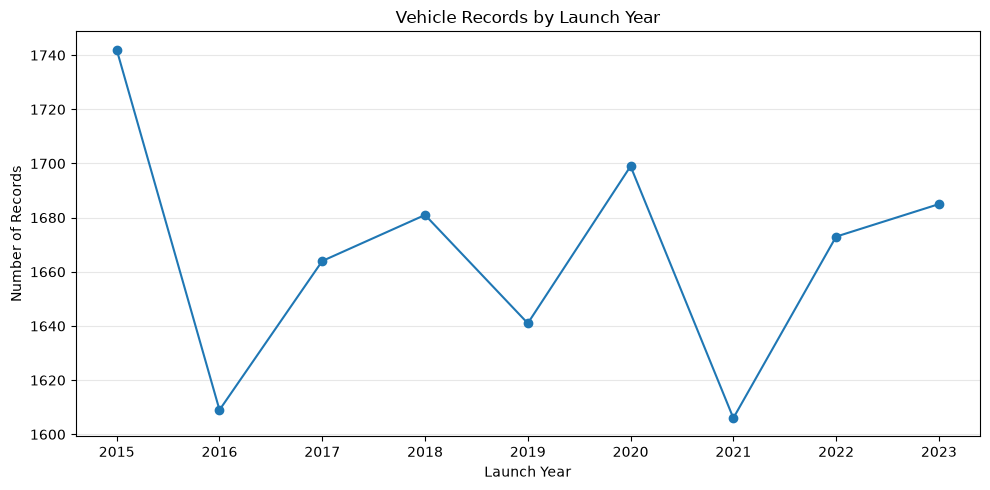

In [34]:
plt.figure(figsize=(10, 5))

plt.plot(
    launch_year_counts.index,
    launch_year_counts.values,
    marker='o'
)

plt.title('Vehicle Records by Launch Year')
plt.xlabel('Launch Year')
plt.ylabel('Number of Records')
plt.xticks(launch_year_counts.index)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**Insight:**  
The number of vehicle records remains relatively consistent across 2015–2023, ranging from 1,606 to 1,742 records per year. 2015 has the highest representation, while 2021 has the lowest. Overall, there is no strong increasing or decreasing trend in the dataset.

### 7.7 Price Analysis

Analyzing vehicle prices helps us understand the overall price distribution of vehicles in the dataset and identify the typical pricing range.

In [35]:
price_stats = df['Average Price (₹ Lakhs)'].describe()

price_stats

count    15000.000000
mean        14.907117
std         13.052186
min          6.000000
25%          7.625000
50%         12.500000
75%         18.500000
max         83.000000
Name: Average Price (₹ Lakhs), dtype: float64

#### Distribution of Average Vehicle Prices

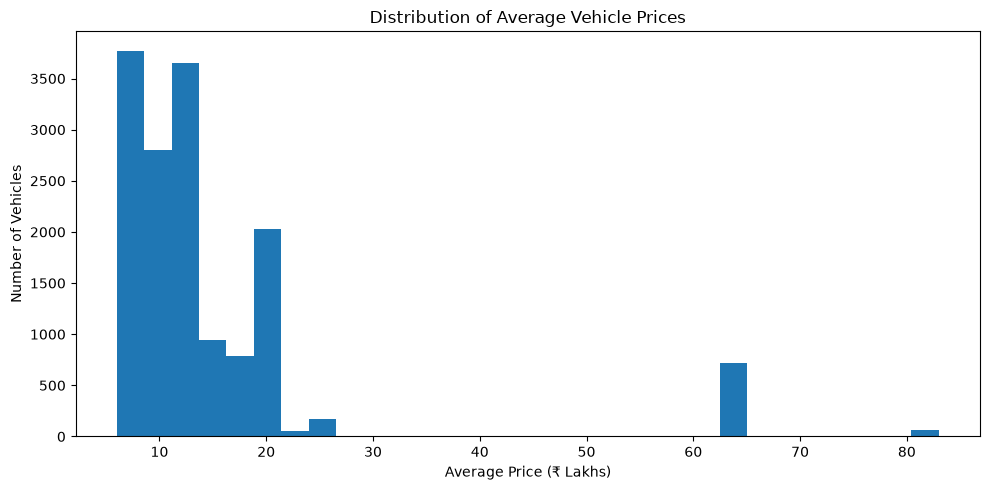

In [36]:
plt.figure(figsize=(10, 5))

plt.hist(df['Average Price (₹ Lakhs)'], bins=30)

plt.title('Distribution of Average Vehicle Prices')
plt.xlabel('Average Price (₹ Lakhs)')
plt.ylabel('Number of Vehicles')
plt.tight_layout()
plt.show()

**Insight:**  
Most vehicles in the dataset are concentrated in the ₹6–20 Lakhs price range. A smaller number of vehicles fall into higher price ranges, extending up to ₹83 Lakhs. The presence of these high-priced vehicles contributes to the right-skewed distribution and causes the mean price (₹14.91 Lakhs) to be higher than the median price (₹12.50 Lakhs).

#### Average Vehicle Price by Segment

In [37]:
segment_avg_price = (
    df.groupby('Segment')['Average Price (₹ Lakhs)']
    .mean()
    .sort_values()
)

segment_avg_price

Segment
Hatchback              6.116287
Electric Hatchback     9.160618
Sedan                 10.718939
Compact SUV           12.761609
MPV                   14.282468
Electric SUV          18.832510
SUV                   20.430587
Luxury                66.381074
Name: Average Price (₹ Lakhs), dtype: float64

#### Average Price by Vehicle Segment

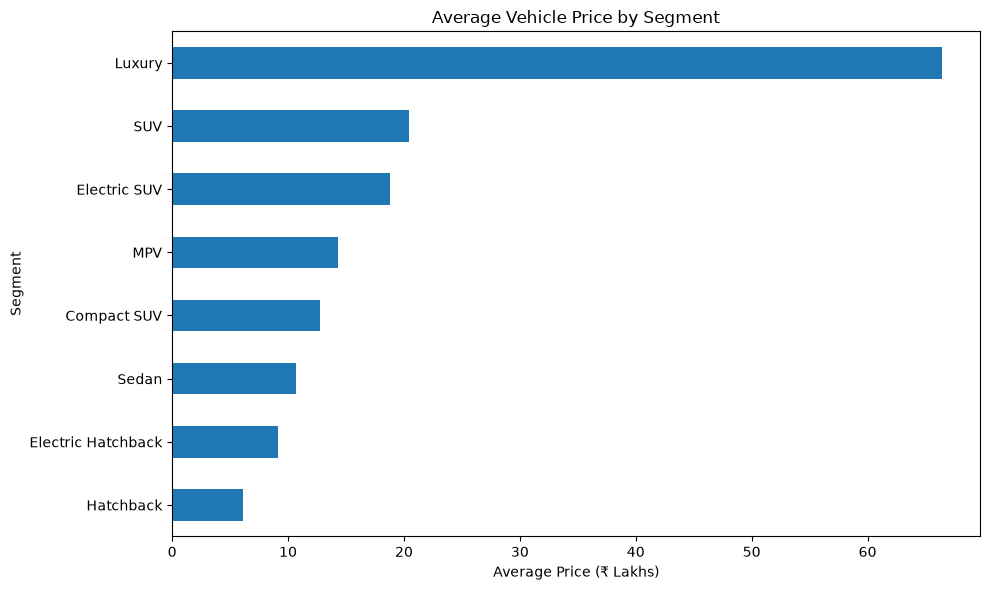

In [38]:
plt.figure(figsize=(10, 6))

segment_avg_price.plot(kind='barh')

plt.title('Average Vehicle Price by Segment')
plt.xlabel('Average Price (₹ Lakhs)')
plt.ylabel('Segment')
plt.tight_layout()
plt.show()

**Insight:**  
Luxury vehicles have the highest average price at approximately ₹66.38 Lakhs, significantly higher than all other segments. Hatchbacks have the lowest average price at approximately ₹6.12 Lakhs. Overall, average vehicle price increases substantially across higher-end and SUV-oriented segments.

### 7.8 Monthly Sales Analysis

Monthly sales represent the number of vehicles sold for each record. Analyzing sales helps identify the overall sales range and understand the distribution of vehicle demand in the dataset.

In [39]:
sales_stats = df['Monthly Sales (Units)'].describe()

sales_stats

count    15000.000000
mean      8664.002200
std       4941.852964
min        150.000000
25%       4563.000000
50%       8521.500000
75%      12368.000000
max      19993.000000
Name: Monthly Sales (Units), dtype: float64

#### Distribution of Monthly Vehicle Sales

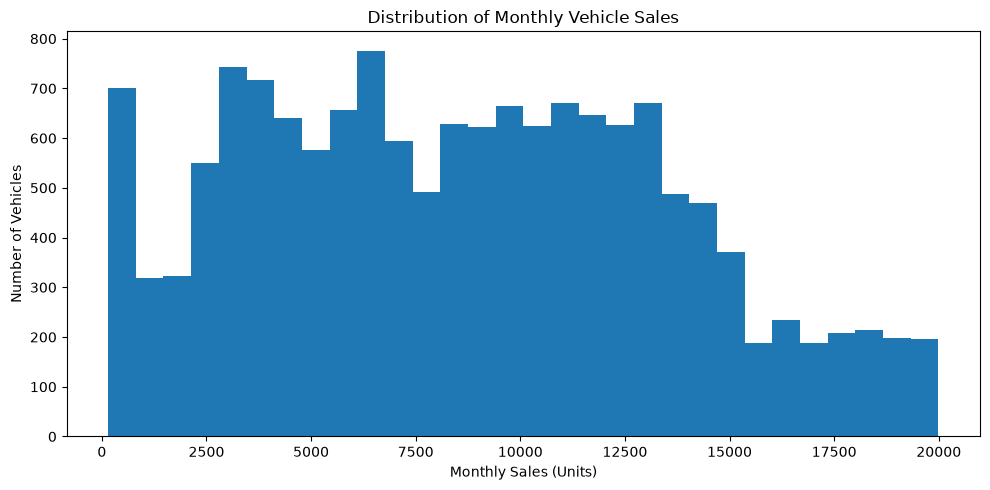

In [40]:
plt.figure(figsize=(10, 5))

plt.hist(df['Monthly Sales (Units)'], bins=30)

plt.title('Distribution of Monthly Vehicle Sales')
plt.xlabel('Monthly Sales (Units)')
plt.ylabel('Number of Vehicles')
plt.tight_layout()
plt.show()

**Insight:**  
Monthly sales range from 150 to 19,993 units, with most vehicle records distributed across the middle of this range. The distribution shows considerable variation in sales, indicating differences in demand across vehicle records.

#### Average Monthly Sales by Vehicle Segment

In [41]:
segment_avg_sales = (
    df.groupby('Segment')['Monthly Sales (Units)']
    .mean()
    .sort_values()
)

segment_avg_sales

Segment
Luxury                  510.249361
Electric SUV           2549.780735
Electric Hatchback     2840.402831
MPV                    4336.384292
SUV                    4735.761493
Sedan                  9021.288632
Compact SUV           10459.128598
Hatchback             13955.318049
Name: Monthly Sales (Units), dtype: float64

#### Average Monthly Sales by Vehicle Segment

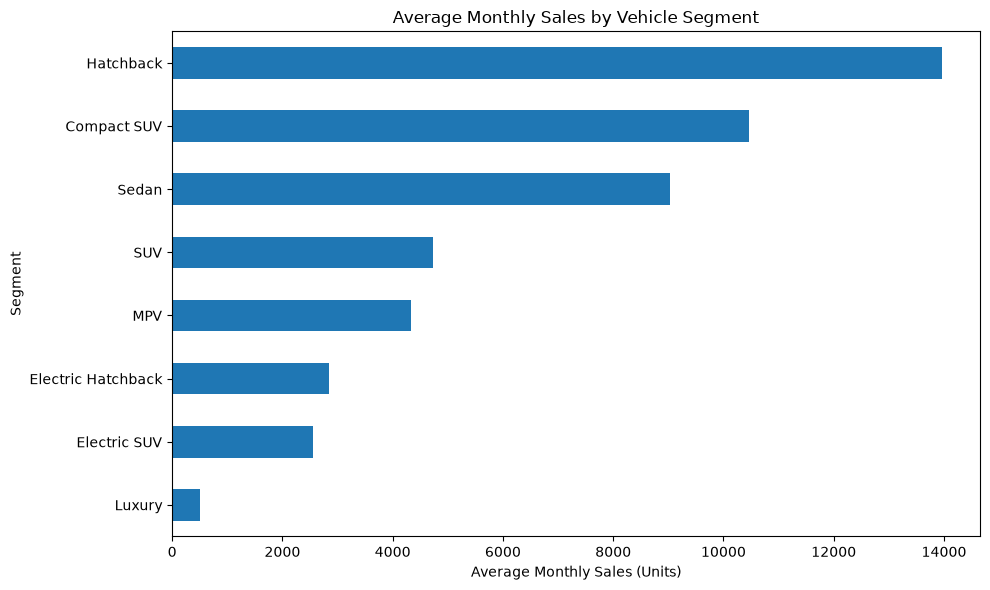

In [42]:
plt.figure(figsize=(10, 6))

segment_avg_sales.plot(kind='barh')

plt.title('Average Monthly Sales by Vehicle Segment')
plt.xlabel('Average Monthly Sales (Units)')
plt.ylabel('Segment')
plt.tight_layout()
plt.show()

**Insight:**  
Hatchbacks have the highest average monthly sales at approximately 13,955 units, followed by Compact SUVs at 10,459 units and Sedans at 9,021 units. Luxury vehicles have the lowest average monthly sales at approximately 510 units. Overall, mass-market segments show substantially higher average sales than premium and electric segments in this dataset.

#### Average Monthly Sales by Brand

In [43]:
brand_avg_sales = (
    df.groupby('Brand')['Monthly Sales (Units)']
    .mean()
    .sort_values()
)

brand_avg_sales

Brand
Skoda            8372.961942
Toyota           8466.505481
Renault          8493.805630
Kia              8511.097204
Mercedes         8518.832902
MG               8541.027344
Honda            8546.287535
Tata             8566.708020
Maruti Suzuki    8648.940945
Force            8669.896138
Mahindra         8677.137042
Lexus            8690.742340
Nissan           8711.447861
BYD              8718.550067
BMW              8803.500692
Audi             8817.829870
Volkswagen       8838.654229
Hyundai          8865.920520
Citroen          8884.698300
Jeep             8998.554469
Name: Monthly Sales (Units), dtype: float64

#### Average Monthly Sales by Brand

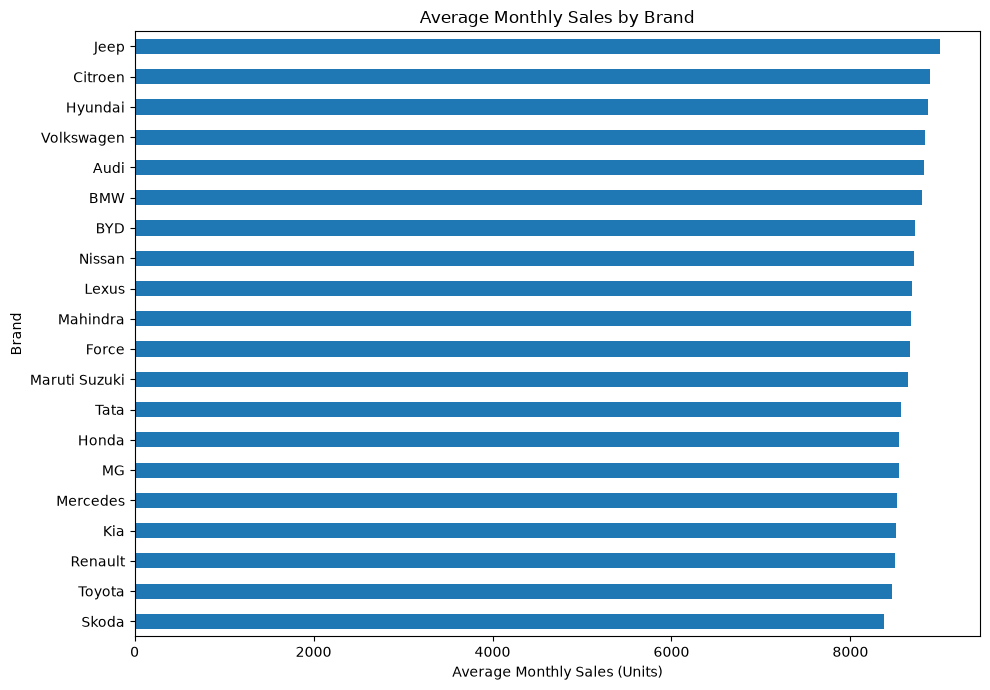

In [44]:
plt.figure(figsize=(10, 7))

brand_avg_sales.plot(kind='barh')

plt.title('Average Monthly Sales by Brand')
plt.xlabel('Average Monthly Sales (Units)')
plt.ylabel('Brand')
plt.tight_layout()
plt.show()

**Insight:**  
Average monthly sales are relatively consistent across brands, ranging from approximately 8,373 units for Skoda to 8,999 units for Jeep. The small difference between the highest and lowest averages indicates that brand alone does not create a large difference in average sales within this dataset.

#### Average Monthly Sales: EV vs Non-EV

In [45]:
ev_avg_sales = (
    df.groupby('Is EV?')['Monthly Sales (Units)']
    .mean()
    .sort_values()
)

ev_avg_sales

Is EV?
Yes    7948.075961
No     8721.715727
Name: Monthly Sales (Units), dtype: float64

#### Average Monthly Sales: EV vs Non-EV

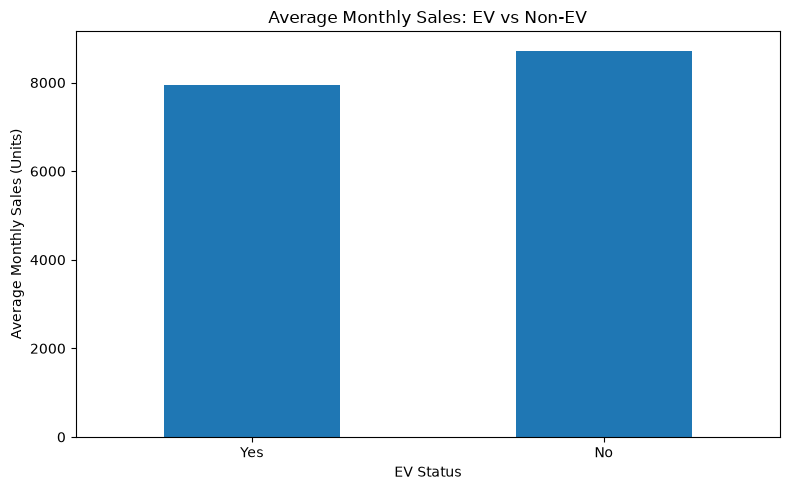

In [46]:
plt.figure(figsize=(8, 5))

ev_avg_sales.plot(kind='bar')

plt.title('Average Monthly Sales: EV vs Non-EV')
plt.xlabel('EV Status')
plt.ylabel('Average Monthly Sales (Units)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Insight:**  
Non-EV vehicles have higher average monthly sales at approximately 8,722 units compared with approximately 7,948 units for EVs. This indicates that EV records have somewhat lower average sales than non-EV records in this dataset.

## 7.9 Variants Analysis

### Distribution of Vehicle Variants

In [47]:
variant_stats = df['Variants'].describe()

variant_stats

count    15000.000000
mean        13.174000
std          7.200239
min          1.000000
25%          7.000000
50%         13.000000
75%         19.000000
max         25.000000
Name: Variants, dtype: float64

### Distribution of Vehicle Variants

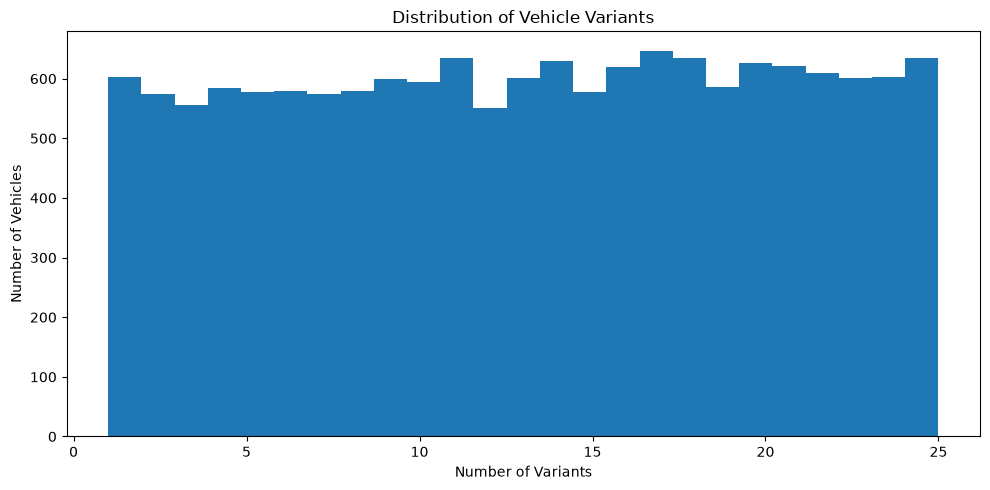

In [48]:
plt.figure(figsize=(10, 5))

plt.hist(df['Variants'], bins=25)

plt.title('Distribution of Vehicle Variants')
plt.xlabel('Number of Variants')
plt.ylabel('Number of Vehicles')
plt.tight_layout()
plt.show()

**Insight:**  
The number of variants is fairly evenly distributed between 1 and 25 across the dataset. There is no strong concentration around a specific variant count, indicating considerable variation in the number of variants offered across vehicle records.

### Relationship Between Variants and Monthly Sales

In [49]:
variant_sales_corr = df['Variants'].corr(df['Monthly Sales (Units)'])

variant_sales_corr

np.float64(-0.0012732693227250087)

**Insight:**  
The correlation between the number of variants and monthly sales is approximately -0.0013, which is effectively zero. This indicates that there is virtually no linear relationship between the number of variants offered and monthly vehicle sales in this dataset.

### Variants vs Monthly Sales

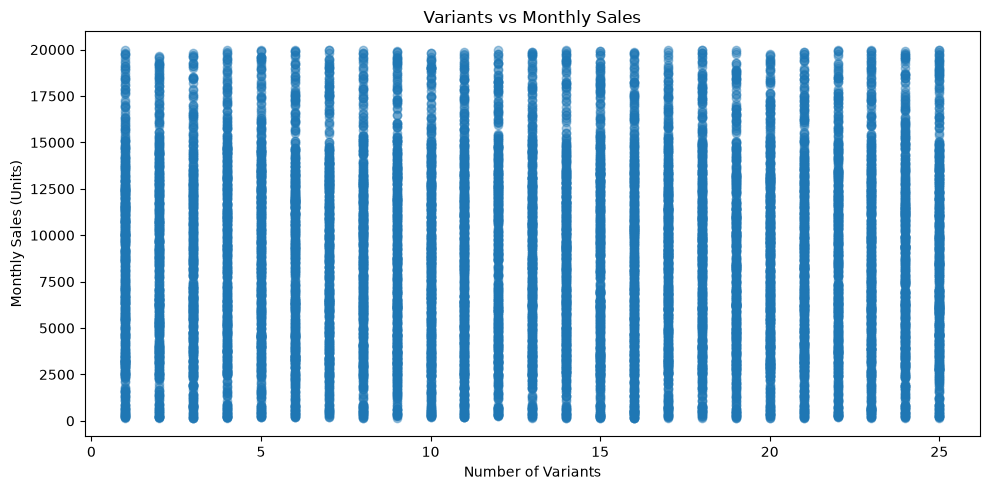

In [50]:
plt.figure(figsize=(10, 5))

plt.scatter(
    df['Variants'],
    df['Monthly Sales (Units)'],
    alpha=0.4
)

plt.title('Variants vs Monthly Sales')
plt.xlabel('Number of Variants')
plt.ylabel('Monthly Sales (Units)')
plt.tight_layout()
plt.show()

**Insight:**  
The scatter plot shows a highly dispersed pattern with no clear upward or downward trend between the number of variants and monthly sales. This supports the near-zero correlation of -0.0013, indicating that the number of variants has virtually no linear relationship with monthly sales in this dataset.

## 7.10 Brand & Segment Comparison

### Average Monthly Sales by Brand and Segment

In [51]:
brand_segment_sales = (
    df.groupby(['Brand', 'Segment'])['Monthly Sales (Units)']
    .mean()
    .unstack()
)

brand_segment_sales

Segment,Compact SUV,Electric Hatchback,Electric SUV,Hatchback,Luxury,MPV,SUV,Sedan
Brand,,,,,,,,
Audi,10435.840000,3052.939394,2437.727273,13859.009615,507.307692,4174.631579,4801.239583,9025.090909
BMW,10829.507772,2918.844444,2441.029412,14082.464706,557.548387,4258.821429,4725.738739,9057.531532
BYD,10429.795000,2839.676471,2523.757576,13844.708995,459.772727,4469.343750,4853.550459,8846.907407
Citroen,10163.603352,2536.375000,2541.725000,14376.519774,548.974359,4735.062500,5007.307692,9458.948276
Force,10566.305556,2653.365854,2642.690476,13993.288136,561.882353,4590.862069,4671.471074,9410.055118
Honda,10316.754839,2782.111111,2626.371429,13940.119318,489.275862,4238.475000,4855.039062,9195.037383
Hyundai,10330.455090,2914.133333,2237.861111,13949.859375,517.161290,4025.400000,4856.783133,8703.628319
Jeep,10785.629834,2762.225000,2479.500000,14410.514563,474.921053,4475.352941,4809.376068,9007.606061
Kia,10437.403509,2795.037037,2734.051724,13619.041237,555.139535,4328.270270,4939.366667,9447.148515


### Brand × Segment: Average Monthly Sales

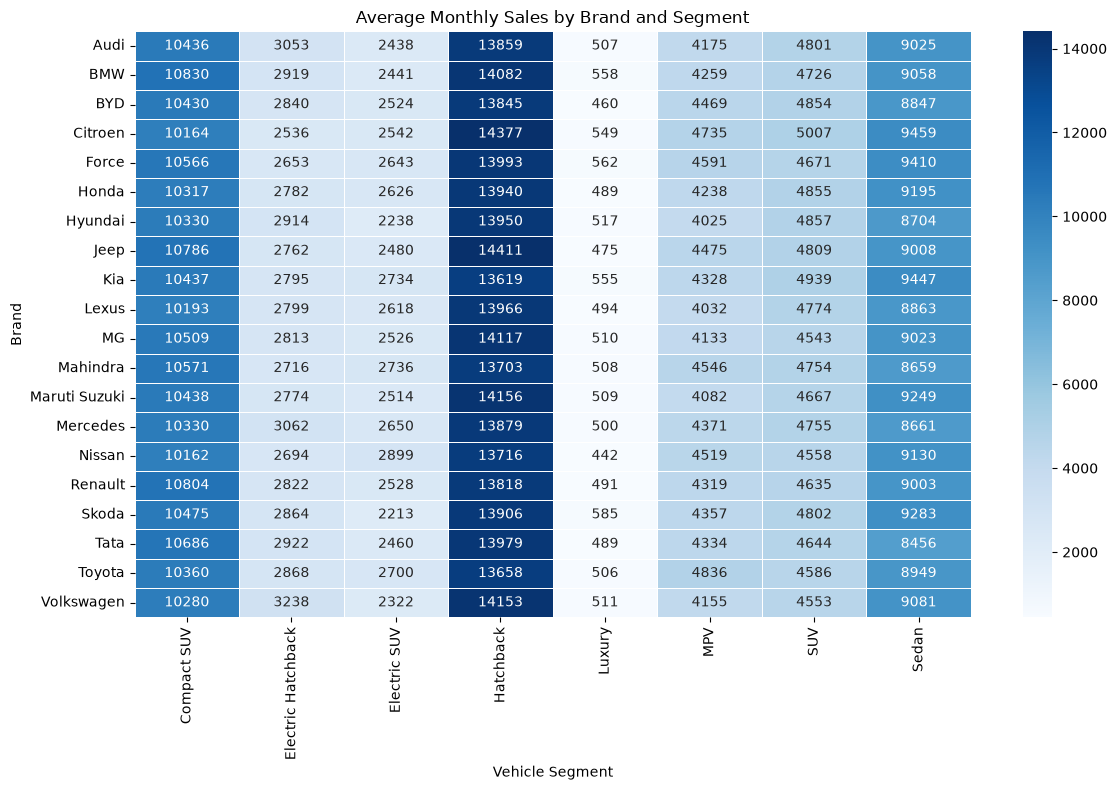

In [52]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    brand_segment_sales,
    annot=True,
    fmt='.0f',
    cmap='Blues',
    linewidths=0.5
)

plt.title('Average Monthly Sales by Brand and Segment')
plt.xlabel('Vehicle Segment')
plt.ylabel('Brand')
plt.tight_layout()
plt.show()

**Insight:**  
The heatmap shows that vehicle segment has a stronger influence on average monthly sales than brand. Hatchbacks and Compact SUVs consistently record the highest average sales across brands, while Luxury vehicles have substantially lower sales. Differences between brands within the same segment are comparatively smaller.

### Average Vehicle Price by Brand and Segment

In [53]:
brand_segment_price = (
    df.groupby(['Brand', 'Segment'])['Average Price (₹ Lakhs)']
    .mean()
    .unstack()
)

brand_segment_price

Segment,Compact SUV,Electric Hatchback,Electric SUV,Hatchback,Luxury,MPV,SUV,Sedan
Brand,,,,,,,,
Audi,12.840000,9.072727,18.500000,6.093750,66.038462,14.300000,20.286458,10.603636
BMW,12.799482,9.106667,18.645588,6.124265,65.580645,14.407143,20.346847,10.654054
BYD,12.755000,9.141176,18.950000,6.103175,67.045455,14.475000,20.302752,10.763889
Citroen,12.822905,9.000000,18.871250,6.146893,66.846154,14.237500,20.241758,10.721121
Force,12.688889,9.058537,18.853571,6.100989,66.588235,14.655172,20.545455,10.724409
Honda,12.916774,9.133333,18.782857,6.129261,65.620690,14.380000,20.171875,10.766355
Hyundai,12.744311,9.240000,18.912500,6.118490,66.161290,14.190000,20.066265,10.676549
Jeep,12.838122,9.180000,18.645588,6.118325,66.894737,14.558824,20.517094,10.845455
Kia,12.738596,9.266667,18.756034,6.134021,65.837209,14.205405,20.550000,10.697525


In [54]:
brand_segment_mileage = df.pivot_table(
    index='Brand',
    columns='Segment',
    values='Mileage (kmpl)',
    aggfunc='mean'
)

brand_segment_mileage

Segment,Compact SUV,Electric Hatchback,Electric SUV,Hatchback,Luxury,MPV,SUV,Sedan
Brand,,,,,,,,
Audi,21.391667,20.565625,21.866667,21.676020,21.610204,21.254286,21.323077,21.458491
BMW,21.103977,20.862791,20.715152,21.542038,20.373333,20.984000,21.321154,21.511429
BYD,21.622703,21.159375,21.863333,21.522034,20.984615,21.246429,21.003883,21.259184
Citroen,21.893210,21.312500,21.029730,21.938509,21.520000,21.963333,21.642529,20.994393
Force,21.163529,21.755000,20.928205,21.266265,21.219355,20.991667,21.222018,21.030769
Honda,21.264706,19.932353,21.112121,21.346296,20.696429,21.975000,21.651613,21.245361
Hyundai,20.935484,22.344444,20.781818,21.329775,22.734483,21.173684,21.697561,21.500000
Jeep,21.708589,20.908108,22.021212,21.527749,21.291176,21.620690,21.950000,21.220690
Kia,21.127673,21.854167,20.683636,21.023034,21.065854,21.571429,21.155556,21.167021


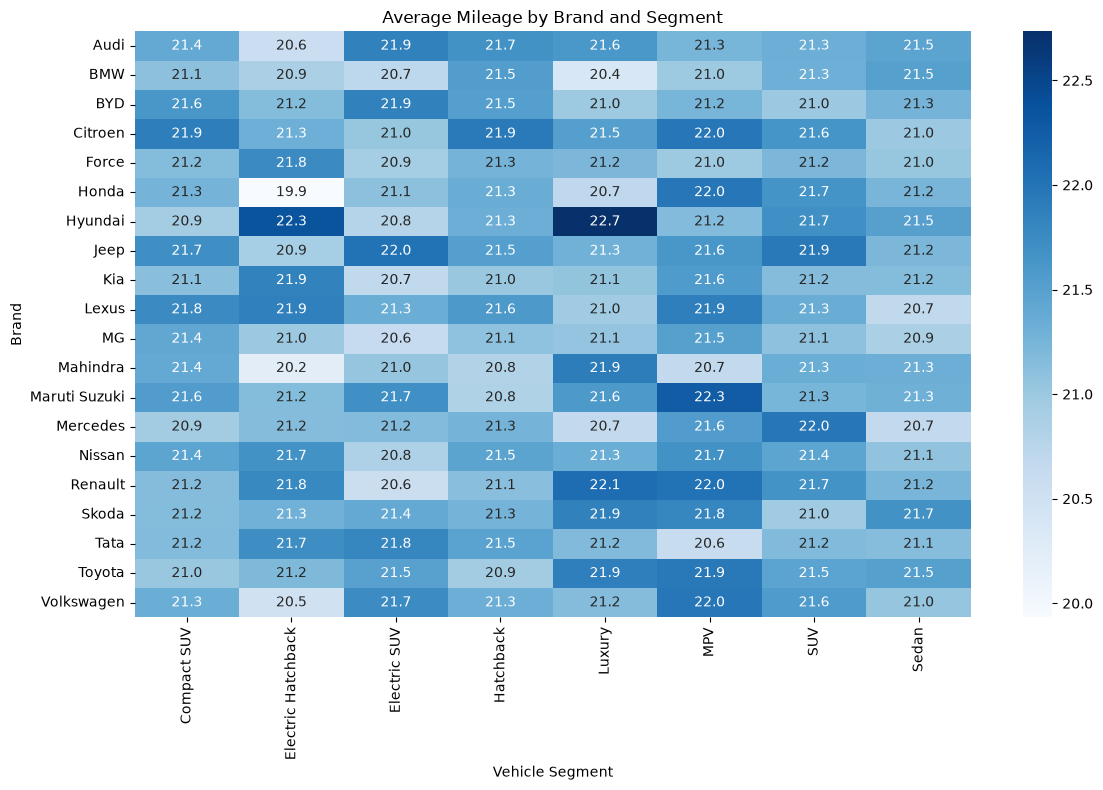

In [55]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    brand_segment_mileage,
    annot=True,
    fmt='.1f',
    cmap='Blues'
)

plt.title('Average Mileage by Brand and Segment')
plt.xlabel('Vehicle Segment')
plt.ylabel('Brand')
plt.tight_layout()
plt.show()

**Insight:**  
The heatmap shows that average mileage is relatively consistent across brands and vehicle segments, with most values ranging between 20–22 km/l. Brand-level differences within the same segment are comparatively small, while certain combinations such as Maruti Suzuki–MPV and Hyundai–Luxury show higher mileage. Overall, neither brand nor segment creates a very large variation in mileage.

### Average Vehicle Price by Brand and Segment

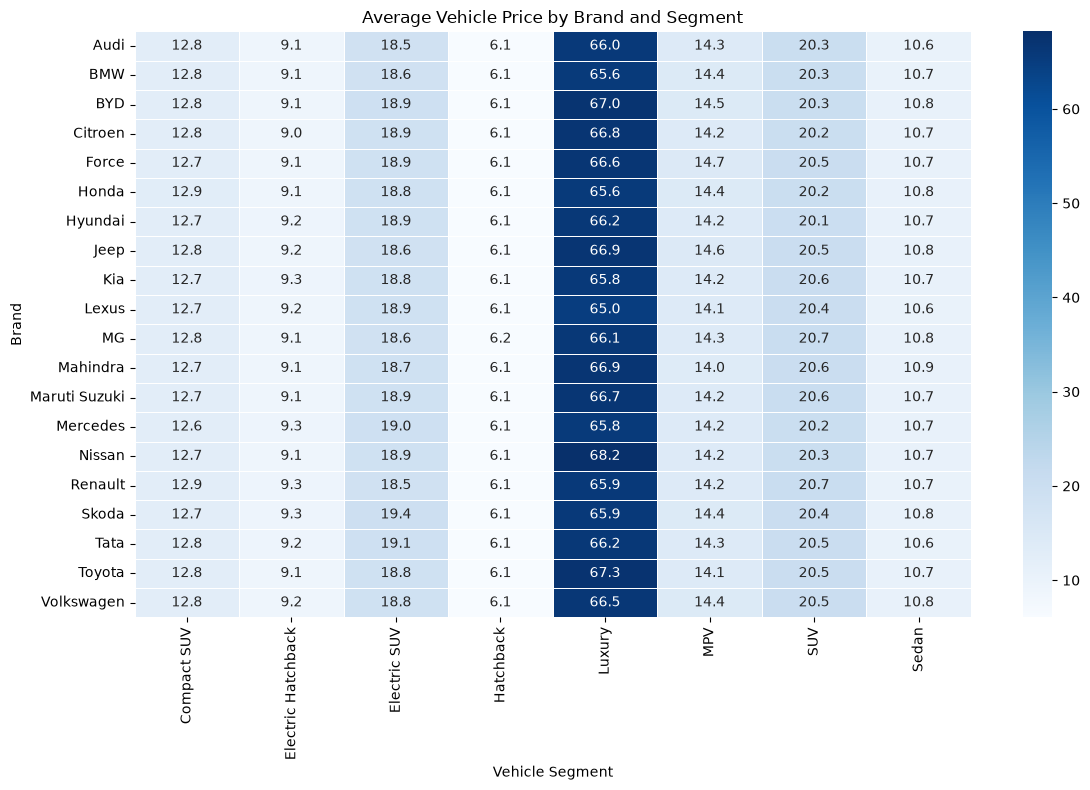

In [56]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    brand_segment_price,
    annot=True,
    fmt='.1f',
    cmap='Blues',
    linewidths=0.5
)

plt.title('Average Vehicle Price by Brand and Segment')
plt.xlabel('Vehicle Segment')
plt.ylabel('Brand')
plt.tight_layout()
plt.show()

### Price vs Monthly Sales

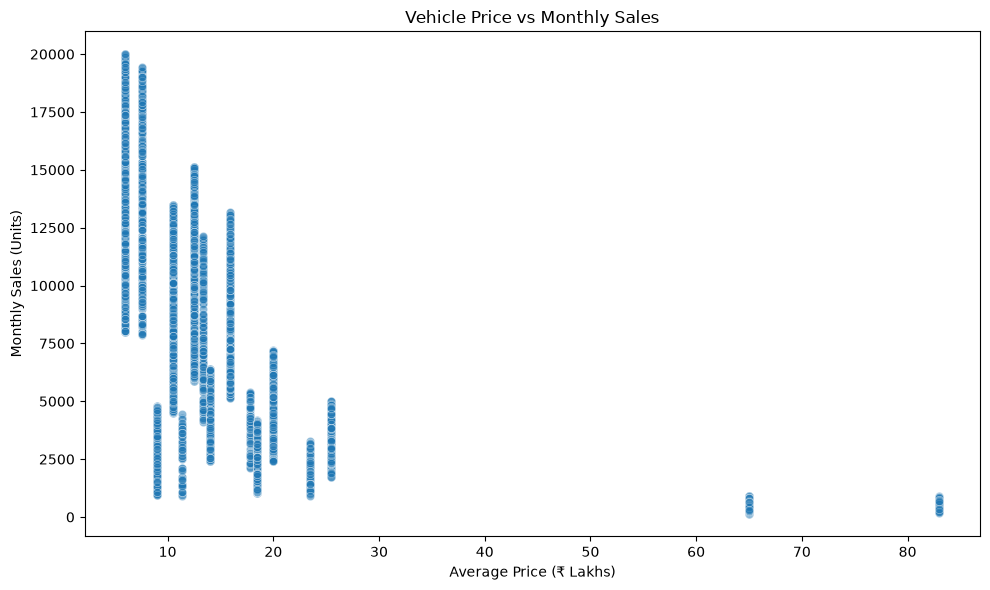

In [57]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Average Price (₹ Lakhs)',
    y='Monthly Sales (Units)',
    alpha=0.5
)

plt.title('Vehicle Price vs Monthly Sales')
plt.xlabel('Average Price (₹ Lakhs)')
plt.ylabel('Monthly Sales (Units)')
plt.tight_layout()
plt.show()

**Insight:**  
The scatter plot shows a clear **negative relationship between vehicle price and monthly sales**. Lower-priced vehicles generally achieve higher monthly sales, while higher-priced vehicles—especially those around ₹65–83 lakhs—have substantially lower sales. This suggests that **vehicle price has a strong influence on sales volume** in this dataset.

In [58]:
df[['Average Price (₹ Lakhs)', 'Monthly Sales (Units)']].corr()

,Average Price (₹ Lakhs),Monthly Sales (Units)
Average Price (₹ Lakhs),1.000000,-0.581993
Monthly Sales (Units),-0.581993,1.000000


**Insight:**  
The correlation between average vehicle price and monthly sales is approximately **-0.58**, indicating a moderate negative relationship. This suggests that higher-priced vehicles generally tend to have lower monthly sales, while lower-priced vehicles tend to achieve higher sales. Therefore, vehicle price appears to have a noticeable influence on sales volume in this dataset.

## 7.11 Variants vs Monthly Sales

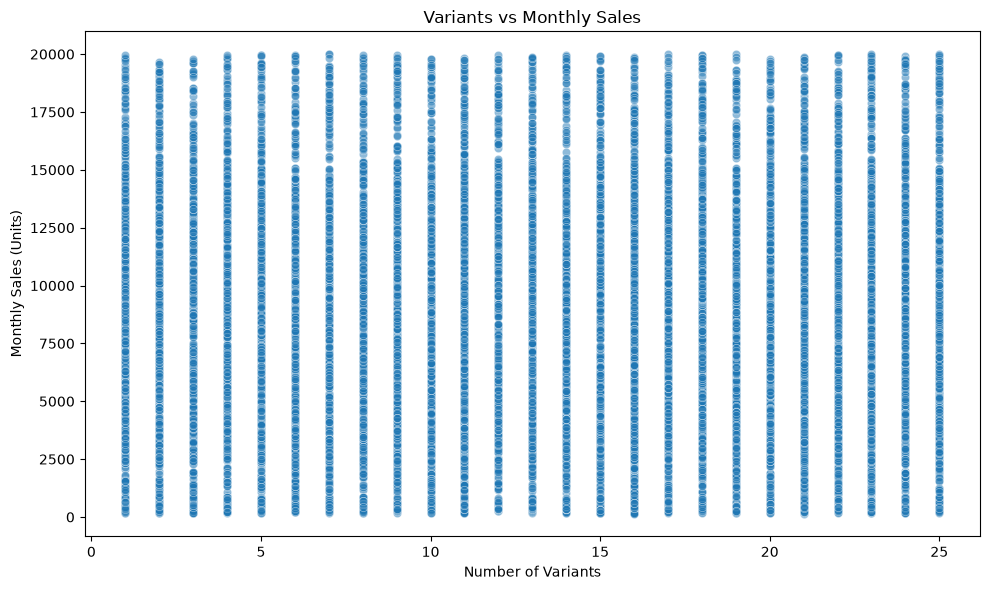

In [59]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Variants',
    y='Monthly Sales (Units)',
    alpha=0.5
)

plt.title('Variants vs Monthly Sales')
plt.xlabel('Number of Variants')
plt.ylabel('Monthly Sales (Units)')
plt.tight_layout()
plt.show()

In [60]:
df[['Variants', 'Monthly Sales (Units)']].corr()

,Variants,Monthly Sales (Units)
Variants,1.000000,-0.001273
Monthly Sales (Units),-0.001273,1.000000


**Insight:**  
The correlation between the number of variants and monthly sales is approximately **-0.001**, indicating virtually no linear relationship between the two variables. This suggests that the number of variants does not show a meaningful linear relationship with monthly sales in this dataset.

## 7.12 Launch Year vs Monthly Sales

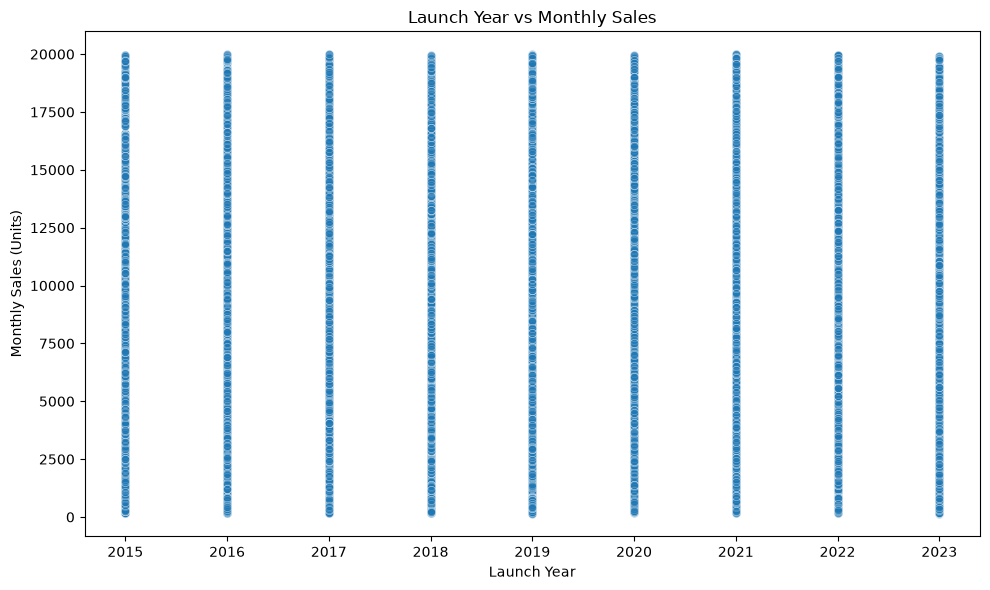

In [61]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Launch Year',
    y='Monthly Sales (Units)',
    alpha=0.5
)

plt.title('Launch Year vs Monthly Sales')
plt.xlabel('Launch Year')
plt.ylabel('Monthly Sales (Units)')
plt.tight_layout()
plt.show()

In [62]:
df[['Launch Year', 'Monthly Sales (Units)']].corr()

,Launch Year,Monthly Sales (Units)
Launch Year,1.000000,0.008841
Monthly Sales (Units),0.008841,1.000000


**Insight:**  
The correlation between launch year and monthly sales is approximately **0.009**, indicating virtually no linear relationship between the two variables. This suggests that launch year does not show a meaningful linear relationship with monthly sales in this dataset.

## 7.13 Average Price vs Variants

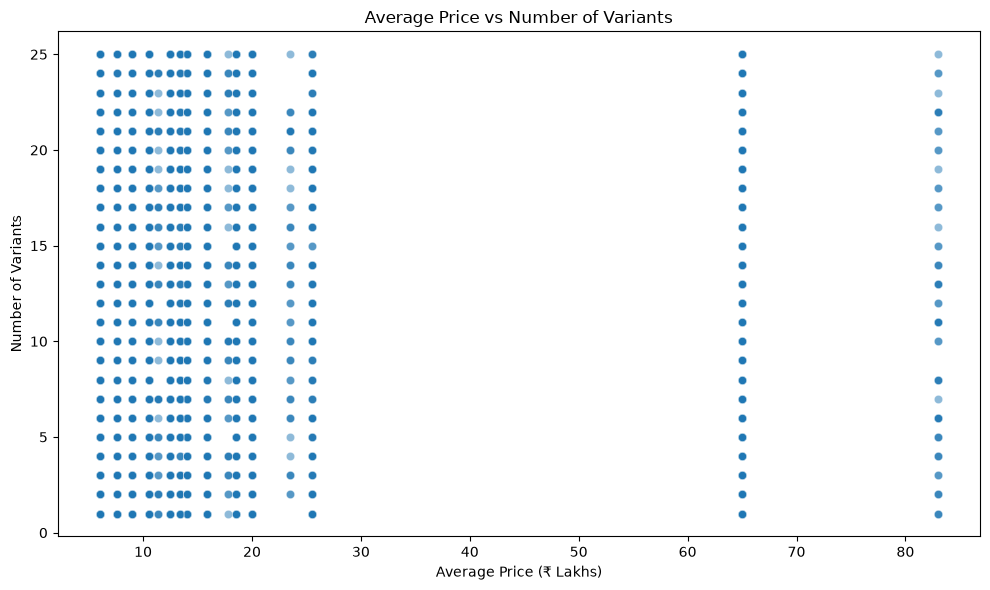

In [63]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Average Price (₹ Lakhs)',
    y='Variants',
    alpha=0.5
)

plt.title('Average Price vs Number of Variants')
plt.xlabel('Average Price (₹ Lakhs)')
plt.ylabel('Number of Variants')
plt.tight_layout()
plt.show()

In [64]:
df[['Average Price (₹ Lakhs)', 'Variants']].corr()

,Average Price (₹ Lakhs),Variants
Average Price (₹ Lakhs),1.000000,-0.002174
Variants,-0.002174,1.000000


**Insight:**  
The correlation between average price and the number of variants is approximately **-0.002**, indicating virtually no linear relationship between the two variables.This suggests that average vehicle price does not show a meaningful linear relationship with the number of variants in this dataset.

## 7.14 Mileage vs Monthly Sales

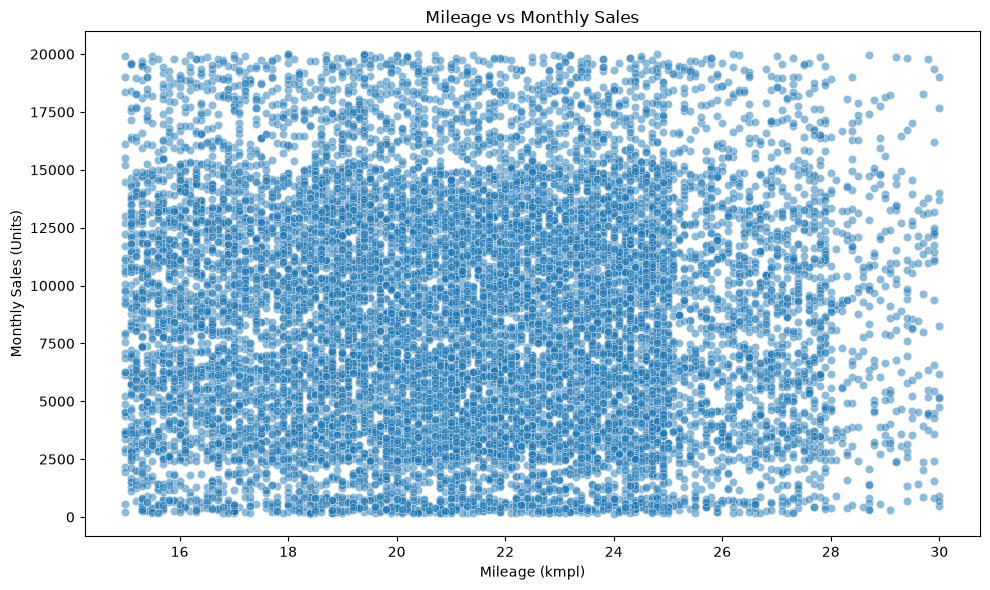

In [65]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Mileage (kmpl)',
    y='Monthly Sales (Units)',
    alpha=0.5
)

plt.title('Mileage vs Monthly Sales')
plt.xlabel('Mileage (kmpl)')
plt.ylabel('Monthly Sales (Units)')
plt.tight_layout()
plt.show()

In [66]:
df[['Mileage (kmpl)', 'Monthly Sales (Units)']].corr()

,Mileage (kmpl),Monthly Sales (Units)
Mileage (kmpl),1.000000,-0.010368
Monthly Sales (Units),-0.010368,1.000000


**Insight:**  
The correlation between mileage and monthly sales is approximately **-0.010**, indicating virtually no linear relationship between the two variables. This suggests that mileage does not show a meaningful linear relationship with monthly sales in this dataset.

## 7.15 Range vs Monthly Sales

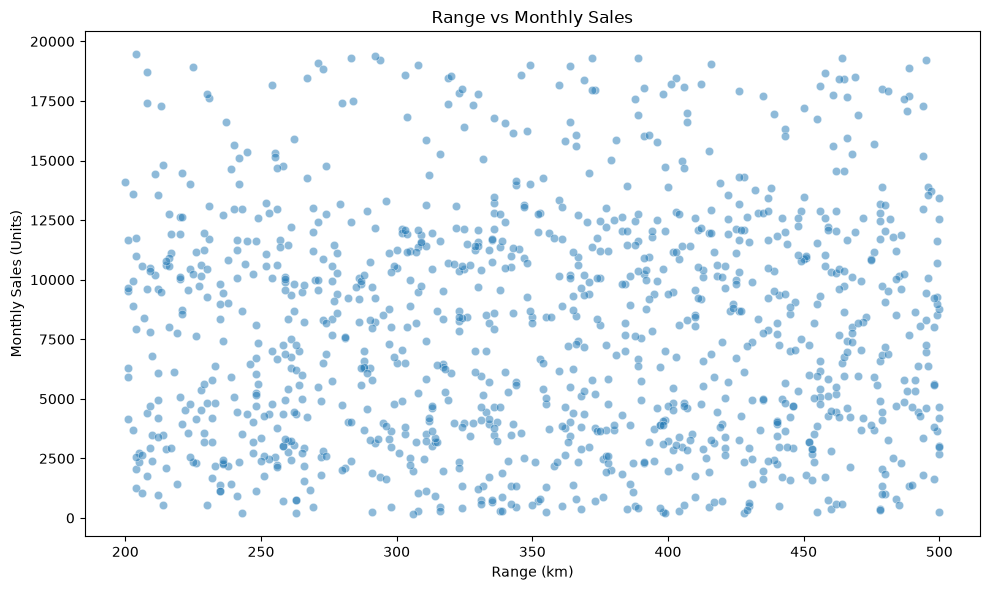

In [67]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Range (km)',
    y='Monthly Sales (Units)',
    alpha=0.5
)

plt.title('Range vs Monthly Sales')
plt.xlabel('Range (km)')
plt.ylabel('Monthly Sales (Units)')
plt.tight_layout()
plt.show()

In [68]:
df[['Range (km)', 'Monthly Sales (Units)']].corr()

,Range (km),Monthly Sales (Units)
Range (km),1.000000,0.036043
Monthly Sales (Units),0.036043,1.000000


**Insight:**  
The correlation between range and monthly sales is approximately **0.036**, indicating virtually no linear relationship between the two variables. This suggests that vehicle range does not show a meaningful linear relationship with monthly sales in this dataset.

## 7.16 Fuel Type vs Monthly Sales

In [69]:
fuel_sales = df.groupby('Fuel Type')['Monthly Sales (Units)'].mean().sort_values(ascending=False)

fuel_sales

Fuel Type
Petrol/Diesel    8950.104019
Diesel           8731.438393
Petrol           8714.680326
Petrol/CNG       8672.659672
Electric         7948.075961
Name: Monthly Sales (Units), dtype: float64

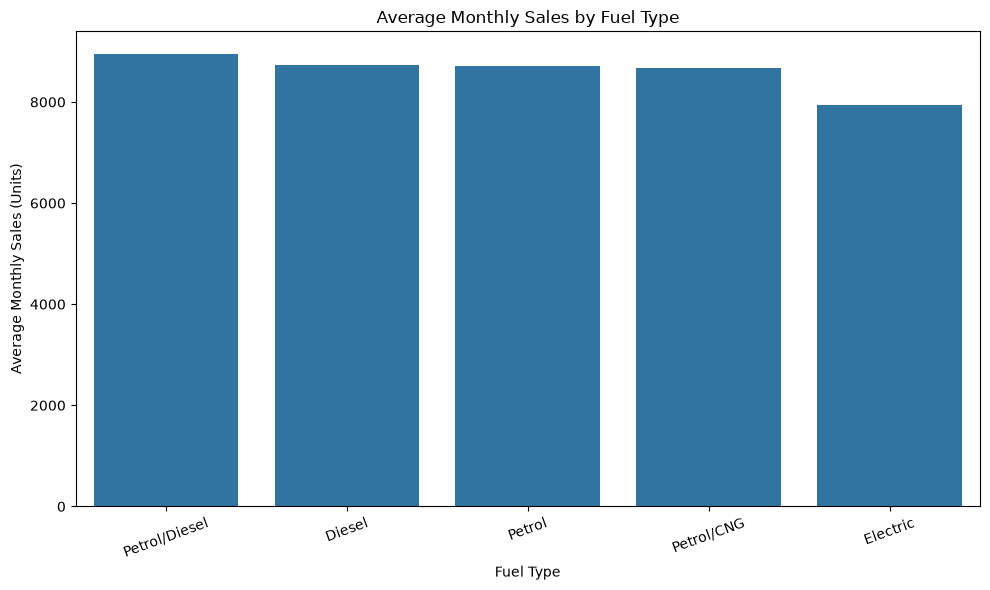

In [70]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=fuel_sales.index,
    y=fuel_sales.values
)

plt.title('Average Monthly Sales by Fuel Type')
plt.xlabel('Fuel Type')
plt.ylabel('Average Monthly Sales (Units)')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

**Insight:**  
Petrol/Diesel vehicles have the highest average monthly sales at approximately 8,950 units, while Electric vehicles have the lowest at approximately 7,948 units. Overall, conventional fuel types show slightly higher average sales than Electric vehicles in this dataset.

## 7.17 Average Price by Fuel Type

In [71]:
fuel_avg_price = df.groupby('Fuel Type')['Average Price (₹ Lakhs)'].mean().sort_values(ascending=False)

fuel_avg_price

Fuel Type
Electric         18.821046
Diesel           14.610272
Petrol           14.593385
Petrol/CNG       14.560984
Petrol/Diesel    14.503546
Name: Average Price (₹ Lakhs), dtype: float64

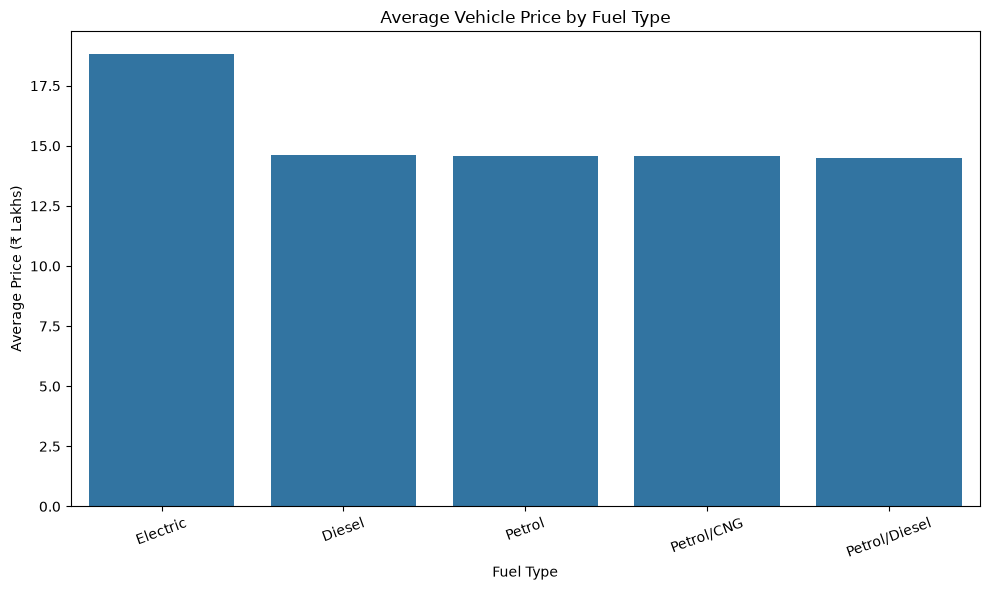

In [72]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=fuel_avg_price.index,
    y=fuel_avg_price.values
)

plt.title('Average Vehicle Price by Fuel Type')
plt.xlabel('Fuel Type')
plt.ylabel('Average Price (₹ Lakhs)')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

**Insight:**  
Electric vehicles have the highest average price at approximately ₹18.82 lakhs, while the average prices of conventional fuel types remain closely grouped around ₹14.50–₹14.61 lakhs. This indicates that EVs are positioned at a higher average price point in this dataset.

## 7.18 EV vs Non-EV Average Price

In [73]:
ev_avg_price = df.groupby('Is EV?')['Average Price (₹ Lakhs)'].mean().sort_values(ascending=False)

ev_avg_price

Is EV?
Yes    18.821046
No     14.591600
Name: Average Price (₹ Lakhs), dtype: float64

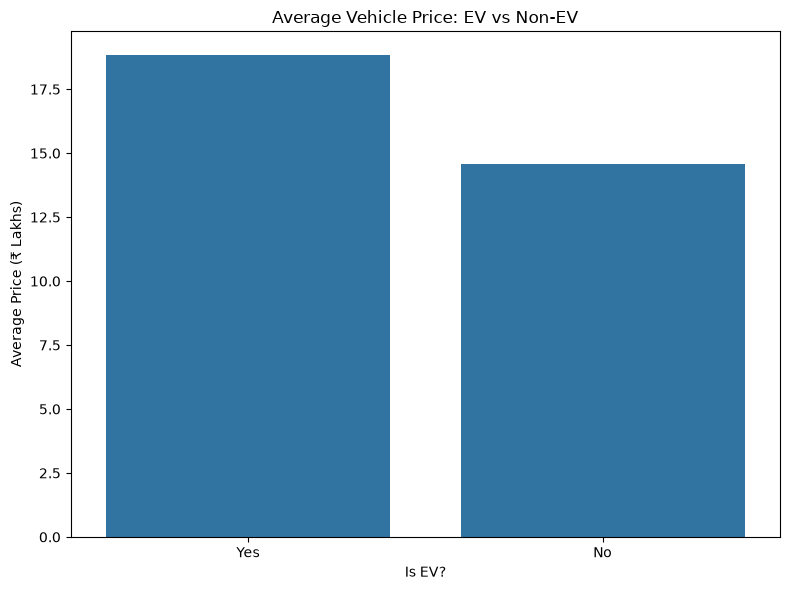

In [74]:
plt.figure(figsize=(8, 6))

sns.barplot(
    x=ev_avg_price.index,
    y=ev_avg_price.values
)

plt.title('Average Vehicle Price: EV vs Non-EV')
plt.xlabel('Is EV?')
plt.ylabel('Average Price (₹ Lakhs)')
plt.tight_layout()
plt.show()

## 7.19 EV vs Non-EV Monthly Sales

In [75]:
ev_avg_sales = df.groupby('Is EV?')['Monthly Sales (Units)'].mean().sort_values(ascending=False)

ev_avg_sales

Is EV?
No     8721.715727
Yes    7948.075961
Name: Monthly Sales (Units), dtype: float64

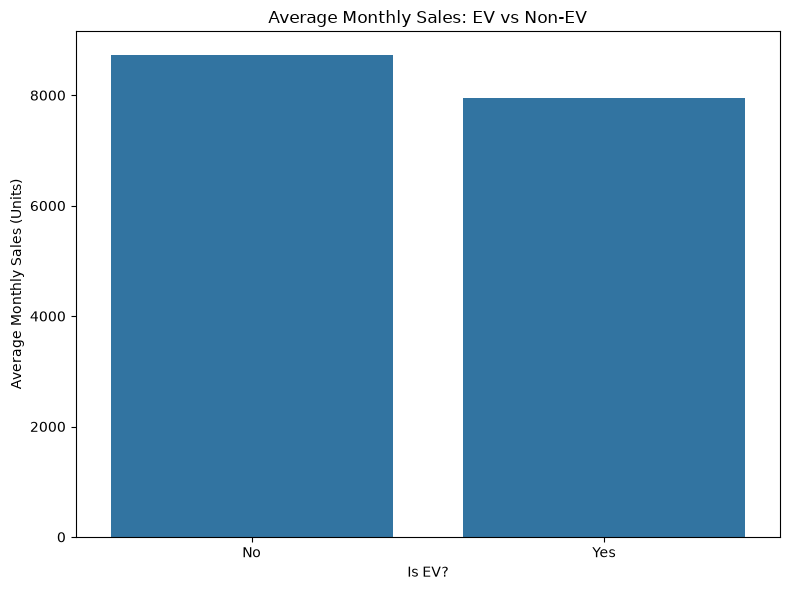

In [76]:
plt.figure(figsize=(8, 6))

sns.barplot(
    x=ev_avg_sales.index,
    y=ev_avg_sales.values
)

plt.title('Average Monthly Sales: EV vs Non-EV')
plt.xlabel('Is EV?')
plt.ylabel('Average Monthly Sales (Units)')
plt.tight_layout()
plt.show()

**Insight:**  
Non-EV vehicles have higher average monthly sales at approximately 8,722 units compared with approximately 7,948 units for EVs. This indicates that conventional vehicles have stronger average sales than EVs in this dataset.

## 7.20 Segment vs Average Price

In [77]:
segment_avg_price = df.groupby('Segment')['Average Price (₹ Lakhs)'].mean().sort_values(ascending=False)

segment_avg_price

Segment
Luxury                66.381074
SUV                   20.430587
Electric SUV          18.832510
MPV                   14.282468
Compact SUV           12.761609
Sedan                 10.718939
Electric Hatchback     9.160618
Hatchback              6.116287
Name: Average Price (₹ Lakhs), dtype: float64

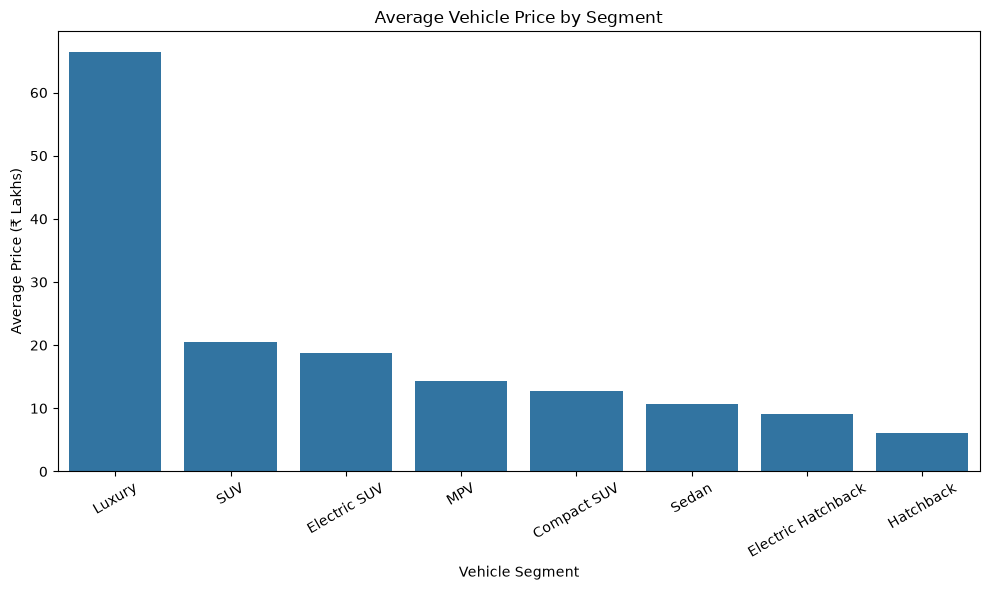

In [78]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=segment_avg_price.index,
    y=segment_avg_price.values
)

plt.title('Average Vehicle Price by Segment')
plt.xlabel('Vehicle Segment')
plt.ylabel('Average Price (₹ Lakhs)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**Insight:**  
Luxury vehicles have the highest average price at approximately ₹66.38 lakhs, significantly higher than all other segments. Hatchbacks have the lowest average price at approximately ₹6.12 lakhs, while SUVs and Electric SUVs occupy the higher-priced mainstream segments.

## 7.21 Final EDA Summary & Key Business Insights

**Key Insights:**

- **Segment has a stronger influence on sales than brand:** Average monthly sales vary considerably across vehicle segments, while differences between brands are comparatively smaller.

- **Hatchbacks and Compact SUVs show strong sales performance:** These segments consistently record higher average monthly sales, whereas Luxury vehicles have substantially lower sales.

- **Price and sales show a moderate negative relationship:** The correlation between Average Price and Monthly Sales is approximately **-0.58**, indicating that higher-priced vehicles generally tend to have lower sales in this dataset.

- **Variants have almost no relationship with sales:** The correlation between the Number of Variants and Monthly Sales is approximately **-0.001**, suggesting that having more variants does not necessarily result in higher sales.

- **Launch year has almost no relationship with sales:** The correlation of approximately **0.009** indicates that vehicle launch year alone does not strongly explain differences in monthly sales.

- **Mileage and range have very weak relationships with sales:** Mileage has a correlation of approximately **-0.01**, while Range has a correlation of approximately **0.04** with monthly sales. These factors show little direct relationship with sales in this dataset.

- **EVs have a higher average price but lower average sales:** EVs have an average price of approximately **₹18.82 lakhs** compared with **₹14.59 lakhs** for Non-EVs, while their average monthly sales are approximately **7,948 units** compared with **8,722 units** for Non-EVs.

- **Fuel type shows differences in both price and sales:** Electric vehicles have the highest average price among fuel types, while Petrol/Diesel vehicles have the highest average monthly sales.

- **Vehicle segment strongly determines price positioning:** Luxury vehicles have the highest average price at approximately **₹66.38 lakhs**, while Hatchbacks have the lowest at approximately **₹6.12 lakhs**.

**Overall Conclusion:**  
The EDA highlights clear differences in vehicle prices and sales across segments and fuel types. Average price shows a moderate negative linear relationship with monthly sales, while variants, launch year, mileage, and range show very weak linear relationships with monthly sales. EVs have a higher average price but lower average monthly sales than Non-EVs in this dataset. These findings provide useful descriptive insights into the dataset and can serve as a foundation for further analysis and dashboard development.